In [1]:
#Note:
#This notebook generates the snapshots for constructing NI-RB surrogate model. Run this before running main.ipynb.
#
#The test case is 2D transient heat conduction in a square plate: a hot spot is placed in the plate at t = 0 and cools down by diffusion
#    dT/dt = kappa * (d2T/dx2 + d2T/dy2),   on [0,1] x [0,1],   T = 0 on all boundaries
#    T(x, y, t=0) = exp(-((x - x0)^2 + (y - 0.5)^2) / (2 * sigma^2))
#
#We have 2 uncertain parameters:  kappa (thermal diffusivity) in [0.002, 0.02] and x0 (horizontal position of the hot spot) in [0.25, 0.75]
#and 1 time parameter:            t in [0, 2]
#
#The parameter space is sampled with Latin Hypercube Sampling (LHS) from the SALib library
#All results are saved as .npy files in the data folder:
#    grid_x.npy, grid_y.npy, times.npy, parameter_bounds.npy
#    training_parameters.npy, training_outputs.npy
#    test_parameters.npy, test_outputs.npy
#    prediction_parameters.npy, prediction_outputs.npy

Hello


In [2]:
#Import external libraries
import numpy
import os
import time
import matplotlib.pyplot as plt

from SALib.sample import latin

In [3]:
#Create the data folder
data_path = os.path.abspath('data')
os.makedirs(data_path, exist_ok=True)

In [4]:
#Define the discretization of our 2D spatio-temporal problem
#
#nx, ny refer to the number of grid points in x and y direction --> every snapshot has nx * ny = 1024 degrees of freedom
#nt refers to the number of saved time steps between t = 0 and t = t_end
#sigma is the width of the initial hot spot
nx, ny = 32, 32
nt     = 21
t_end  = 2.0
sigma  = 0.08

x = numpy.linspace(0, 1, nx)
y = numpy.linspace(0, 1, ny)
X, Y = numpy.meshgrid(x, y)
times = numpy.linspace(0, t_end, nt)

In [5]:
#Define the parameter space for SALib
#
#SALib describes the uncertain parameters with a "problem" dictionary:
#num_vars is the number of parameters
#names are the parameter names (the order is kept in every saved parameter array)
#bounds are the [lower, upper] bounds of each parameter
problem = {
    'num_vars': 2,
    'names': ['kappa', 'x0'],
    'bounds': [[0.002, 0.020],
               [0.250, 0.750]]
}

In [6]:
#Latin Hypercube Sampling with SALib
#
#For this purpose, we use this function: latin.sample(problem, N, seed=None)
#N is the number of samples; seed ensures reproducibility
#Every set uses a different seed, so the training, test, and prediction samples are different from each other
#    training set   --> used to build the reduced basis and to train the network
#    test set       --> used by BOHB to select the best hyperparameters
#    prediction set --> never seen during the offline phase; used to check the online phase
no_training_samples   = 40
no_test_samples       = 10
no_prediction_samples = 3

training_parameters   = latin.sample(problem, no_training_samples, seed=1)
test_parameters       = latin.sample(problem, no_test_samples, seed=2)
prediction_parameters = latin.sample(problem, no_prediction_samples, seed=3)

print("Training parameters: " + str(training_parameters.shape))
print("Test parameters: " + str(test_parameters.shape))
print("Prediction parameters: " + str(prediction_parameters.shape))

Training parameters: (40, 2)
Test parameters: (10, 2)
Prediction parameters: (3, 2)


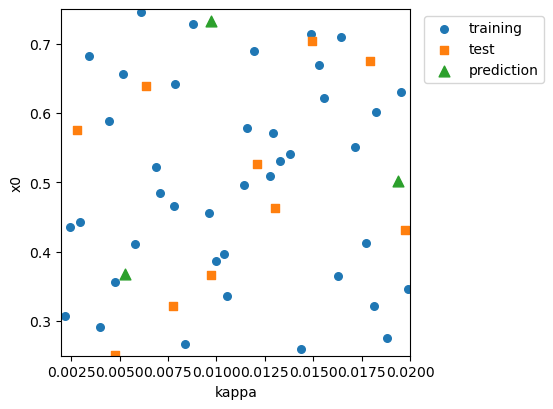

In [7]:
#Show the samples in the parameter space
plt.figure(figsize=(4.5,4.5))
plt.scatter(training_parameters[:,0], training_parameters[:,1], s=30, label='training')
plt.scatter(test_parameters[:,0], test_parameters[:,1], s=30, marker='s', label='test')
plt.scatter(prediction_parameters[:,0], prediction_parameters[:,1], s=60, marker='^', label='prediction')
plt.xlim(problem['bounds'][0])
plt.ylim(problem['bounds'][1])
plt.margins(0)
plt.xlabel(problem['names'][0])
plt.ylabel(problem['names'][1])
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()

In [8]:
#This is our full-order simulator (the expensive model that NI-RB will replace)
#We solve the heat equation with explicit finite differences
#In your own work, you can replace this function with any simulator (e.g., Lattice-Boltzmann, FEM, ...)
#The only requirement is that it returns an array with the size (number of time steps, number of degrees of freedom)
kappa_max = problem['bounds'][0][1]

def heat_simulator(kappa, x0):

    h  = x[1] - x[0]
    dt_save = t_end / (nt - 1)
    steps_per_save = int(numpy.ceil(dt_save / (0.2 * h * h / max(kappa_max, kappa)))) #stable explicit time step
    dt = dt_save / steps_per_save

    #Initial condition
    T = numpy.exp(-((X - x0)**2 + (Y - 0.5)**2) / (2 * sigma**2))
    T[0, :] = T[-1, :] = T[:, 0] = T[:, -1] = 0.0 #Dirichlet boundary

    snapshots = numpy.zeros((nt, ny * nx))
    snapshots[0, :] = T.flatten()

    for kk in range(1, nt):
        for _ in range(steps_per_save):
            laplacian = (T[2:, 1:-1] + T[:-2, 1:-1] + T[1:-1, 2:] + T[1:-1, :-2] - 4 * T[1:-1, 1:-1]) / (h * h)
            T[1:-1, 1:-1] = T[1:-1, 1:-1] + dt * kappa * laplacian
        snapshots[kk, :] = T.flatten()

    return snapshots

In [9]:
#Run the full-order simulator for all samples (snapshot generation)
#
#The output arrays have the size (number of samples, number of time steps, number of degrees of freedom)
#This is the format required by the spatio-temporal NI-RB in CAC
start = time.time()
training_outputs   = numpy.asarray([heat_simulator(*p) for p in training_parameters])
test_outputs       = numpy.asarray([heat_simulator(*p) for p in test_parameters])
prediction_outputs = numpy.asarray([heat_simulator(*p) for p in prediction_parameters])
print("Simulation time: " + str(round(time.time() - start, 2)) + " s")
print("Training outputs: " + str(training_outputs.shape))
print("Test outputs: " + str(test_outputs.shape))
print("Prediction outputs: " + str(prediction_outputs.shape))

Simulation time: 0.13 s
Training outputs: (40, 21, 1024)
Test outputs: (10, 21, 1024)
Prediction outputs: (3, 21, 1024)


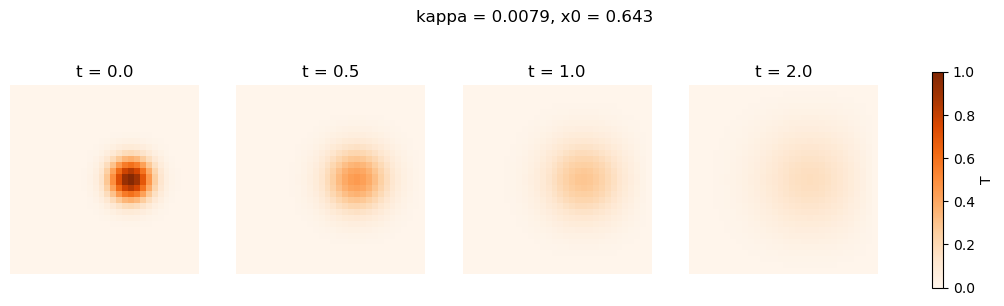

In [10]:
#Show one training simulation at 4 different times
sample = 0
fig, axs = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, kk in zip(axs, [0, 5, 10, 20]):
    im = ax.imshow(training_outputs[sample, kk, :].reshape(ny, nx), origin='lower', extent=[0,1,0,1], cmap='Oranges', vmin=0, vmax=1)
    ax.set_title('t = ' + str(round(times[kk], 2)))
    ax.axis('off')
fig.colorbar(im, ax=axs, shrink=0.8, label='T')
fig.suptitle('kappa = ' + str(round(training_parameters[sample,0], 4)) + ', x0 = ' + str(round(training_parameters[sample,1], 3)))
plt.show()

In [11]:
#Save everything as .npy files
#Parameter arrays have the size (number of samples, number of parameters), with the column order of problem['names']
numpy.save(data_path + '/grid_x.npy', x)
numpy.save(data_path + '/grid_y.npy', y)
numpy.save(data_path + '/times.npy', times)
numpy.save(data_path + '/parameter_bounds.npy', numpy.asarray(problem['bounds']))

numpy.save(data_path + '/training_parameters.npy', training_parameters)
numpy.save(data_path + '/training_outputs.npy', training_outputs)
numpy.save(data_path + '/test_parameters.npy', test_parameters)
numpy.save(data_path + '/test_outputs.npy', test_outputs)
numpy.save(data_path + '/prediction_parameters.npy', prediction_parameters)
numpy.save(data_path + '/prediction_outputs.npy', prediction_outputs)

for ff in sorted(os.listdir(data_path)):
    if ff.endswith('.npy'):
        print(ff + ': ' + str(numpy.load(data_path + '/' + ff).shape))

grid_x.npy: (32,)
grid_y.npy: (32,)
parameter_bounds.npy: (2, 2)
prediction_outputs.npy: (3, 21, 1024)
prediction_parameters.npy: (3, 2)
test_outputs.npy: (10, 21, 1024)
test_parameters.npy: (10, 2)
times.npy: (21,)
training_outputs.npy: (40, 21, 1024)
training_parameters.npy: (40, 2)
